In [11]:
import piplite
await piplite.install('openpyxl')

import piplite
await piplite.install('seaborn')

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.options.display.float_format = '{:.2f}'.format

df = pd.read_excel('Маркетинговые данные.xlsx')
df.info()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 16 entries, 0 to 15
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Марка           16 non-null     str    
 1   Модель          16 non-null     object 
 2   Цена            16 non-null     float64
 3   Валюта          3 non-null      str    
 4   Маржинальность  16 non-null     float64
 5   Вариант 2       0 non-null      float64
 6   Вариант 2.1     0 non-null      float64
dtypes: float64(4), object(1), str(2)
memory usage: 776.0+ bytes


Марка              0
Модель             0
Цена               0
Валюта            13
Маржинальность     0
Вариант 2         16
Вариант 2.1       16
dtype: int64

In [16]:
df = df.drop(columns=['Вариант 2', 'Вариант 2.1'], errors='ignore')

df['Марка'] = df['Марка'].str.title()
df['Модель'] = df['Модель'].str.upper()

df.head()

,Марка,Модель,Цена,Валюта,Маржинальность
0,Mercedes,GLS,113513.51,$,0.33
1,Mercedes,GT_AMG,174324.32,NaN,0.34
2,Bmw,X5,72222.22,Евро,0.27
3,Bmw,I3,51666.67,NaN,0.35
4,Mercedes,С180,2300000.00,Рубль,0.20


In [18]:
df['Валюта'] = df['Валюта'].fillna('Рубль')
df['Валюта'] = df['Валюта'].replace({'$': 'Доллар'})

exchange_rates = {
    'Рубль': 1.0,
    'Доллар': 90.0,
    'Евро': 100.0
}

df['Курс'] = df['Валюта'].map(exchange_rates)
df['Цена_руб'] = df['Цена'] * df['Курс']
df[['Марка', 'Модель', 'Цена', 'Валюта', 'Цена_руб']].head()

,Марка,Модель,Цена,Валюта,Цена_руб
0,Mercedes,GLS,113513.51,Доллар,10216216.22
1,Mercedes,GT_AMG,174324.32,Рубль,174324.32
2,Bmw,X5,72222.22,Евро,7222222.22
3,Bmw,I3,51666.67,Рубль,51666.67
4,Mercedes,С180,2300000.00,Рубль,2300000.00


In [19]:
sales_summary = df.groupby('Марка').agg(
    Всего_выручка_руб=('Цена_руб', 'sum'),
    Средняя_цена_руб=('Цена_руб', 'mean'),
    Количество=('Цена_руб', 'count')
).reset_index().sort_values(by='Всего_выручка_руб', ascending=False)

sales_summary

,Марка,Всего_выручка_руб,Средняя_цена_руб,Количество
1,Mercedes,43040540.54,4304054.05,10
0,Bmw,20223888.89,3370648.15,6


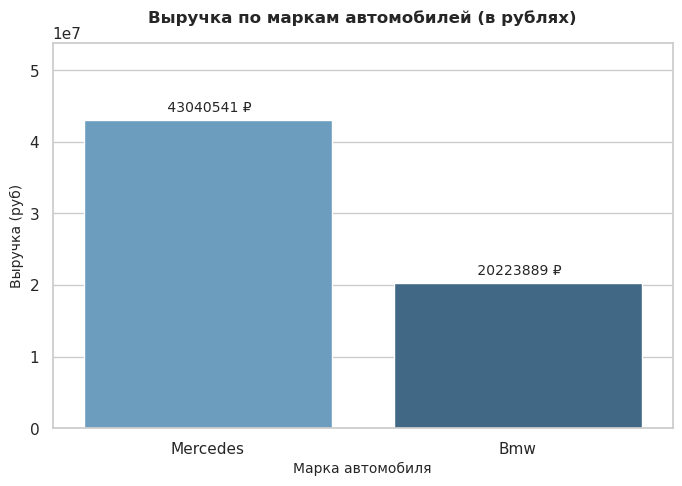

In [26]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=sales_summary, 
    x='Марка', 
    y='Всего_выручка_руб', 
    hue='Марка', 
    palette='Blues_d', 
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f} ₽'.replace(',', ' '), padding=4, fontsize=10)

plt.title('Выручка по маркам автомобилей (в рублях)', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Марка автомобиля', fontsize=10)
plt.ylabel('Выручка (руб)', fontsize=10)
plt.ylim(0, sales_summary['Всего_выручка_руб'].max() * 1.25)

plt.show()